# Make a PSF for a simple exoplanet

This tutorial is a Jupyter notebook, located at `docs/tutorials/exoplanet-psf.ipynb` in the project.

Read the notebook on this page, or download {download}`exoplanet-psf.ipynb <exoplanet-psf.ipynb>` to run it locally.

**Next step:** [Select phantoms and prepare particle inputs](../running-atris/prepare-simulation.md#optionally-select-phantoms).

Let's give a rocky world an atmosphere: **80% nitrogen and 20% carbon dioxide by number**. Choose its size and surface conditions, calculate the profiles, and save the planet as `simulation.psf`.

The PSF divides the planet into finite volumes: concentric spherical shells, each with its own material properties. We will calculate the atmosphere, add the solid planet beneath it, and write one row per shell.

Make it your own: warm it up, give it more carbon dioxide, or turn up the gravity. Start with the profiles below, then try a temperature that falls with altitude or a composition that changes between layers. AtRIS reads the properties of each layer from the PSF.

Run the notebook in your simulation directory, with the AtRIS Python tools, NumPy, and Matplotlib installed.

## 1. Choose the planet

Use SI units for the calculation: metres, kilograms, kelvin, and pascals. Change these values and rerun the notebook to see how the atmosphere responds.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from atris_tools.psf import build_psf, write_psf

radius = 1.5 * 6.371e6     # m; 1.5 Earth radii
mass = 4.0 * 5.9722e24     # kg; 4 Earth masses
temperature = 300.0       # K
surface_pressure = 1e5   # Pa (1 bar)
top = 100e3              # m; atmosphere extends to 100 km
n_layers = 50

## 2. Mix the gases

`co2_fraction = 0.20` means 20 CO₂ molecules out of every 100; the remaining
80 are N₂. Try changing it to `0.60` and rerun the notebook.

For molecular number fractions $x_i$, the mixture's mean molar mass is

$$
M=\sum_i x_i M_i.
$$

A larger share of the heavier CO₂ raises $M$. Look for the effect on the scale
height in the next step.

In [2]:
co2_fraction = 0.20
n2_fraction = 1 - co2_fraction
mole_fraction = np.array([n2_fraction, co2_fraction])
molecule_masses = np.array([28.0134, 44.0095]) / 1000  # kg/mol; N₂, CO₂
molar_mass = np.sum(mole_fraction * molecule_masses)

print(f"Mean molar mass: {molar_mass * 1000:.2f} g/mol")

Mean molar mass: 31.21 g/mol


## 3. Calculate the atmosphere

For an isothermal atmosphere with constant gravity, pressure decreases with altitude $z$ as

$$
P(z)=P_0\exp\left(-\frac{z}{H}\right),\qquad
H=\frac{RT}{Mg},\qquad g=\frac{Gm}{r^2}.
$$

$P_0$ is surface pressure, $H$ is scale height, $T$ is temperature, $M$ is the
mean molar mass of the gas mixture, and $m$ and $r$ are the planet's mass and radius.
The ideal-gas relation gives density:

$$
\rho(z)=\frac{P(z)M}{RT}.
$$

In the code, `surface_pressure`, `scale_height`, and `molar_mass` correspond to
$P_0$, $H$, and $M$.

Divide the atmosphere into `n_layers` finite volumes. Each volume lies between a lower and upper altitude; we evaluate pressure and density at its midpoint and use those values throughout the shell. Here, 50 shells cover 100 km, so each is 2 km thick. Try increasing `n_layers` to resolve the profiles more finely.

`edges[:-1]` leaves out the last boundary and `edges[1:]` leaves out the first, pairing the bottom and top of each shell. NumPy then calculates all the midpoint values at once. Constant gravity is an approximation for an atmosphere thin compared with the planet's radius.

In [3]:
G = 6.67430e-11       # gravitational constant, m³ kg⁻¹ s⁻²
R = 8.314462618       # gas constant, J mol⁻¹ K⁻¹

gravity = G * mass / radius**2
scale_height = R * temperature / (molar_mass * gravity)

edges = np.linspace(0, top, n_layers + 1)
lower_altitude = edges[:-1]
upper_altitude = edges[1:]
altitude = (lower_altitude + upper_altitude) / 2
pressure = surface_pressure * np.exp(-altitude / scale_height)
density = pressure * molar_mass / (R * temperature)  # kg/m³

print(f"Gravity: {gravity:.2f} m/s²")
print(f"Scale height: {scale_height / 1000:.2f} km")

Gravity: 17.46 m/s²
Scale height: 4.58 km


## 4. Plot the profiles

These are the profiles we will put in the PSF. Pressure and density span many
orders of magnitude, so we use logarithmic horizontal axes. The composition
panel shows the two molecular number fractions. They stay constant with altitude
in this well-mixed atmosphere.

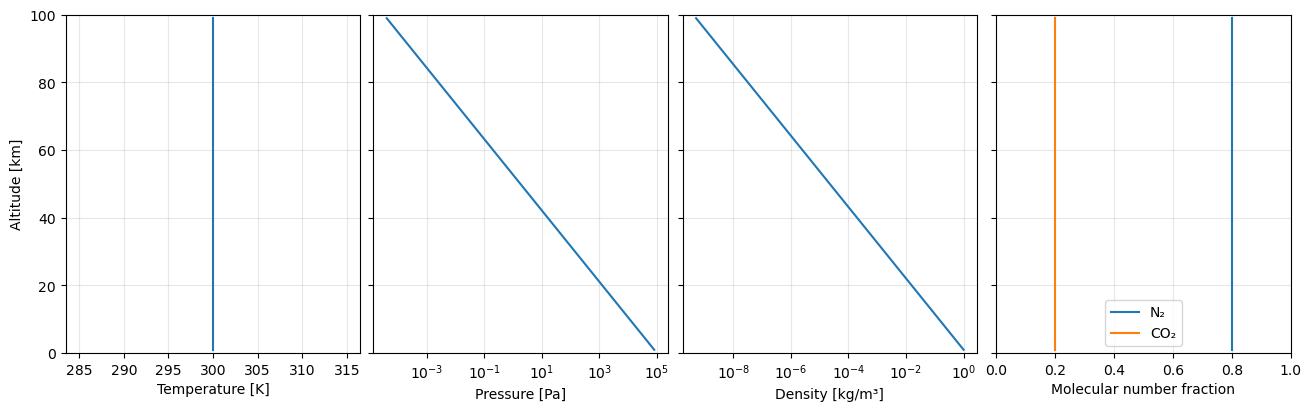

In [4]:
fig, (ax_temperature, ax_pressure, ax_density, ax_composition) = plt.subplots(
    1, 4, figsize=(13, 4), sharey=True, layout="constrained"
)
altitude_km = altitude / 1000

ax_temperature.plot(np.full(n_layers, temperature), altitude_km)
ax_temperature.set_xlabel("Temperature [K]")
ax_temperature.set_ylabel("Altitude [km]")
ax_temperature.set_ylim(0, top / 1000)

ax_pressure.semilogx(pressure, altitude_km)
ax_pressure.set_xlabel("Pressure [Pa]")

ax_density.semilogx(density, altitude_km)
ax_density.set_xlabel("Density [kg/m³]")

ax_composition.plot(np.full(n_layers, n2_fraction), altitude_km, label="N₂")
ax_composition.plot(np.full(n_layers, co2_fraction), altitude_km, label="CO₂")
ax_composition.set_xlabel("Molecular number fraction")
ax_composition.set_xlim(0, 1)
ax_composition.legend()

for ax in fig.axes:
    ax.grid(alpha=0.3)
plt.show()

## 5. Write `simulation.psf`

**The PSF (Planet Specification Format) describes the planet's geometry and material in each layer.** Each numeric row is one spherical shell: where it starts and ends, what it is made of, and its temperature, density, and pressure. Particle energies and event counts are specified separately.

The first two rows describe the solid interior and a thin surface layer, followed by one row for each atmospheric volume. The final row is an outer stopping shell. Radii are measured **from the planet's centre**.

### From molecules to elements

We chose the atmosphere by counting molecules, but the PSF needs **elemental mass fractions**. Nitrogen molecules contribute two nitrogen atoms each; carbon dioxide contributes one carbon and two oxygen atoms. For our mixture, the elemental mass contributions are proportional to

$$
m_N=0.8\times28.0134,\qquad m_C=0.2\times12.0107,\qquad m_O=0.2\times31.9988.
$$

Divide each contribution by their sum to obtain the mass fractions. The code
uses `n2_fraction` and `co2_fraction`, so these update when you change the mixture.


In [5]:
element_mass = np.array([
    n2_fraction * 28.0134,  # nitrogen from N₂
    co2_fraction * 12.0107,  # carbon from CO₂
    co2_fraction * 31.9988,  # oxygen from CO₂
])
element_fractions = element_mass / element_mass.sum()
print("Mass fractions [N, C, O]:", element_fractions)

Mass fractions [N, C, O]: [0.71800189 0.07696054 0.20503758]


### The material header

After the descriptive comments, the material-definition line is:

```text
O533Si467 N C O
```

`O533Si467` gives the solid interior's oxygen and silicon mass weights, 533:467.
`N C O` names the three elemental mass-fraction columns at the end of each row.
Gas rows contain the fractions we just calculated. The solid rows have zeros in
those columns and use the header's solid composition.

### The first four rows

Here is a rounded preview for the default parameters. The file itself contains
whitespace-separated numbers; `head` below will show the values you generate.

| Inner radius (km) | Outer radius (km) | φ start (rad) | φ end (rad) | θ start (rad) | θ end (rad) | ID | T (K) | Density (g/cm³) | Pressure (Pa) | State | N | C | O |
| ---: | ---: | ---: | ---: | ---: | ---: | ---: | ---: | ---: | ---: | ---: | ---: | ---: | ---: |
| 0 | 9556.48 | 0 | 6.28319 | 0 | 3.14159 | 0 | 300 | 2.7 | 100000 | 1 | 0 | 0 | 0 |
| 9556.48 | 9556.50 | 0 | 6.28319 | 0 | 3.14159 | 1 | 300 | 2.7 | 100000 | 1 | 0 | 0 | 0 |
| 9556.5 | 9558.50 | 0 | 6.28319 | 0 | 3.14159 | 2 | 300 | 0.00100577 | 80375.4 | 0 | 0.718002 | 0.076961 | 0.205038 |
| 9558.5 | 9560.50 | 0 | 6.28319 | 0 | 3.14159 | 3 | 300 | 0.000649746 | 51924.1 | 0 | 0.718002 | 0.076961 | 0.205038 |

Read row **ID 2** as: a nitrogen–carbon dioxide mixture between 9556.5 and
9558.5 km from the centre, or **0–2 km altitude**. Its pressure and density are
evaluated at the 1 km midpoint. The final three columns give the nitrogen,
carbon, and oxygen mass fractions.

The angular bounds `0 … 2π` and `0 … π` make complete spherical shells.
State `1` selects solid material and `0` selects gas.

### Assemble the layers

`build_psf` puts named quantities into the right columns and keeps the element
names with the table. It also supplies the full-sphere angles and sequential IDs.

We still choose the physical layers: a solid interior, a 20 m surface layer,
our atmosphere, and a 20 m outer stopping shell starting 1 m above it.
`np.concatenate` joins the interior, atmosphere, and stopping shell in that order.
The Boolean array `is_atmosphere` identifies the gas volumes; the other rows
use the solid composition.

In [6]:
radius_km = radius / 1000
stopping_radius = (radius + top) / 1000 + 0.001

inner_radii = np.concatenate((
    [0, radius_km - 0.02],           # solid interior and surface
    (radius + lower_altitude) / 1000,
    [stopping_radius],
))
outer_radii = np.concatenate((
    [radius_km - 0.02, radius_km],
    (radius + upper_altitude) / 1000,
    [stopping_radius + 0.02],
))
is_atmosphere = (inner_radii >= radius_km) & (outer_radii <= (radius + top) / 1000)
nitrogen, carbon, oxygen = element_fractions

Now pass the profiles and composition to the builder. Temperature is a single
value shared by every layer; density and pressure have one value per layer.
The argument names show the units, so we convert kg/m³ to g/cm³ here.

In [7]:
psf = build_psf(
    inner_radius_km=inner_radii,
    outer_radius_km=outer_radii,
    temperature_k=temperature,
    density_g_cm3=np.concatenate(([2.7, 2.7], density / 1000, [2.7])),
    pressure_pa=np.concatenate(([surface_pressure, surface_pressure], pressure, [surface_pressure])),
    state=np.where(is_atmosphere, "gas", "solid"),
    mass_fractions={
        "N": nitrogen * is_atmosphere,
        "C": carbon * is_atmosphere,
        "O": oxygen * is_atmosphere,
    },
    solid_composition="O533Si467",
)

### Save and inspect the file

`write_psf` handles the descriptive header and number formatting, using the
material names stored by `build_psf`. `psf.formats("%.3e")` uses three decimal
places in scientific notation for the material properties, while preserving
the geometry and integer IDs and states.

In [8]:
write_psf("simulation.psf", psf, fmt=psf.formats("%.3e"))

Use `head` to see the file's header and first four layers. The `!` runs a shell command from a notebook cell.

In [9]:
!head -n 10 simulation.psf

# AtRIS Planet Specification Format (PSF)
# Units: radii km; angles rad; temperature K; density g/cm3; pressure Pa.
# Columns: r_inner r_outer phi_start phi_end theta_start theta_end detector_id temperature density pressure state N C O
# Material columns are mass fractions. State: 0 gas, 1 solid, 2 liquid.
# All-zero solid fractions use the compact composition in the material definition:
O533Si467 N C O
0.0 9556.48 0.0 6.283185307179586 0.0 3.141592653589793 0 3.000e+02 2.700e+00 1.000e+05 1 0.000e+00 0.000e+00 0.000e+00
9556.48 9556.5 0.0 6.283185307179586 0.0 3.141592653589793 1 3.000e+02 2.700e+00 1.000e+05 1 0.000e+00 0.000e+00 0.000e+00
9556.5 9558.5 0.0 6.283185307179586 0.0 3.141592653589793 2 3.000e+02 1.006e-03 8.038e+04 0 7.180e-01 7.696e-02 2.050e-01
9558.5 9560.5 0.0 6.283185307179586 0.0 3.141592653589793 3 3.000e+02 6.497e-04 5.192e+04 0 7.180e-01 7.696e-02 2.050e-01


The PSF is ready. To turn it into geometry, run:

```bash
atris-psf-to-gdml simulation.psf
```

That produces `simulation.gdml`. Continue with [phantom selection](../running-atris/prepare-simulation.md#optionally-select-phantoms), then prepare the particle inputs. Phantoms are optional.

For other gas mixtures, see [gas composition](../reference/inputs.md#layer-composition). The [PSF reference](../reference/inputs.md#planet-specification-format-psf) describes every column. The outer shell is a numerical stopping boundary, not part of the physical atmosphere.

**Next step:** [Select phantoms and prepare particle inputs](../running-atris/prepare-simulation.md#optionally-select-phantoms).
